# Proyecto Oráculo · Descenso de coordenadas

**Análisis y Diseño de Algoritmos · 2026-B · Grupo 1 (ADAG1)**

## Objetivo

Encontrar la **configuración de prompt** —un índice de 0 a 7 para cada ranura (`rol`, `estrategia`, `formato`, `estilo`, `cierre`) más la temperatura— que maximice la fracción de instancias cuyas restricciones verificables se cumplen **todas** (puntaje todo-o-nada, hasta 5 restricciones por instancia). El modelo (Qwen3-1.7B) y su verificador forman un oráculo de caja negra: dada una configuración y un lote de instancias, devuelve la precisión y las trazas de lo que falló.

```
r = oraculo.evaluar(config, instancias, semilla)   # precisión y trazas sobre un lote
r_val = oraculo.validar(config, n)                 # partición de validación, muestra fija
```

El espacio contiene 8⁵ = **32 768** configuraciones con temperatura 0.0. Evaluar una sola sobre las 100 instancias de búsqueda cuesta unos 200 s en una GPU T4, por lo que explorar el espacio completo es inviable y se recurre a una búsqueda guiada.

## Enfoque de este notebook

Se implementa **descenso de coordenadas**: partiendo de una configuración inicial, se mejora **una ranura a la vez**, evaluando las otras siete opciones de esa ranura con las demás fijas y adoptando la mejor solo si supera estrictamente a la actual. La búsqueda se ejecutó **dos veces**, para separar el efecto del algoritmo del efecto del punto de partida:

| Ejecución | Punto de partida | Precisión inicial | Precisión final (búsqueda, n = 100) |
|---|---|---|---|
| A | Aleatorio | 5,0 % | 12,0 % |
| B | Configuración de menor intrusión del catálogo | 16,0 % | **20,0 %** |

## Resultado

La configuración final es `{rol: 6, estrategia: 2, formato: 0, estilo: 6, cierre: 3, temperatura: 0.0}`, con **20,0 %** en búsqueda (100 instancias) y **23,0 %** en validación (87 instancias no usadas para buscar). Es la mejor configuración encontrada, no un óptimo global demostrado: se evaluaron 72 de las 32 768 configuraciones.

## Organización

1. Entorno · 2. Modelo · 3. Oráculo y datos · 4. Algoritmo y ejecuciones · 5. Resultados · 6. Trazas de fallos y decisiones · 7. Validación · 8. Entrega · 9. Conclusiones.

## 1 · Entorno

La celda siguiente instala las librerías que usan el modelo y los verificadores (`transformers`, `accelerate`, `bitsandbytes`, `nltk`, `spacy`, `emoji`, `langdetect`, `immutabledict`), clona `open-instruct` (verificadores de restricciones) y descarga `oraculo.py`, `ayudas.py` y `datos_visibles.json` del repositorio del curso. Los datos de `nltk` se descargan manualmente porque su descargador no funciona con el proxy de Colab.

**Tras ejecutarla se reinicia el entorno de ejecución** antes de continuar: de lo contrario `transformers` puede quedar parcialmente instalado y `cargar_modelo` falla con un error poco informativo.

In [1]:
# bitsandbytes: checkpoints 4-bit (qwen8b, mistral7b). nltk/spacy/emoji/langdetect:
# los usa el verificador de open-instruct, no el notebook.
!pip install -q -U "bitsandbytes>=0.46.1" transformers accelerate \
                   nltk spacy emoji langdetect immutabledict
!python -m spacy download en_core_web_sm -q
!git clone -q https://github.com/allenai/open-instruct

REPO = "https://raw.githubusercontent.com/DanielMelo404/Proyecto-Oraculo-AyD/main"
# --no-cache: Colab a veces reusa un ayudas.py viejo y el alias no existe.
!wget -q --no-cache -O oraculo.py {REPO}/oraculo.py
!wget -q --no-cache -O ayudas.py {REPO}/ayudas.py
!wget -q --no-cache -O datos_visibles.json {REPO}/datos_visibles.json

# Los datos de nltk se bajan a mano: su downloader rechaza el proxy de Colab.
import io
import urllib.request
import zipfile

NLTK_DATA = "https://raw.githubusercontent.com/nltk/nltk_data/gh-pages/packages"
PAQUETES = [
    ("tokenizers", "punkt"),
    ("tokenizers", "punkt_tab"),
    ("taggers", "averaged_perceptron_tagger"),
    ("taggers", "averaged_perceptron_tagger_eng"),
]
for carpeta, nombre in PAQUETES:
    with urllib.request.urlopen(f"{NLTK_DATA}/{carpeta}/{nombre}.zip") as resp:
        zipfile.ZipFile(io.BytesIO(resp.read())).extractall(f"/root/nltk_data/{carpeta}")

print("LISTO  →  Entorno de ejecución ▸ Reiniciar sesión, y sigue en la celda 2")


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
LISTO  →  Entorno de ejecución ▸ Reiniciar sesión, y sigue en la celda 2


## 2 · Modelo

Se usa `qwen17b` (`Qwen/Qwen3-1.7B`) en fp16 sobre una GPU T4 (*Entorno de ejecución ▸ Cambiar tipo de entorno de ejecución ▸ T4 GPU*), con el modo de pensamiento apagado. Ocupa unos 3,4 GB de VRAM, lo que permite generar lotes de 16 prompts a la vez, y es el más rápido de los modelos disponibles (`ministral3b`, `llama3b`, `qwen8b`, `mistral7b`).

El nombre del modelo forma parte de la clave de la caché del oráculo: cambiar de modelo no reutiliza respuestas anteriores. Todas las cifras de este notebook corresponden a `qwen17b`.

In [2]:
from ayudas import cargar_modelo

# Alias → checkpoint. El nombre entra en la clave de caché: si cambian de
# modelo, las respuestas anteriores no se reusan.
#  "qwen17b"     → Qwen/Qwen3-1.7B
#  "ministral3b" → mistralai/Ministral-3-3B-Instruct-2512-BF16
#  "llama3b"     → unsloth/Llama-3.2-3B-Instruct
modelo = cargar_modelo("qwen17b")


cargando qwen17b → Qwen/Qwen3-1.7B


config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

... (3 outputs left out)

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Qwen/Qwen3-1.7B  VRAM: 3.44 GB


## 3 · Oráculo y datos

`dividir` parte `datos_visibles.json` (450 instancias) en tres grupos:

| Partición | Instancias | Uso |
|---|---|---|
| `busqueda` | 100 | única partición sobre la que se busca |
| `validacion` | 87 | se usa solo para validar la configuración ya elegida |
| descartadas | 263 | no miden nada útil (ver `dividir`) y se excluyen |

Con 100 instancias de búsqueda, un cambio de una instancia equivale a un punto porcentual; con menos, las configuraciones cercanas al piso se confunden con cero. La validación mide la **generalización a instancias nuevas de las mismas familias de restricciones**; no mide generalización a familias nuevas.

La caché del oráculo se guarda en Google Drive (`oraculo_cache.json`) para sobrevivir a desconexiones de Colab; los resultados ya generados no se vuelven a calcular.

In [4]:
# Descomenten estas dos líneas si quieren que el caché sobreviva a una
# desconexión: el path de Drive reemplaza cache_oraculo.json local.
from google.colab import drive
drive.mount("/content/drive")

from oraculo import Oraculo, CATALOGO, espacio
from ayudas import cargar_datos, dividir

datos = cargar_datos()
busqueda, validacion = dividir(datos)
# 1.7B en fp16 deja VRAM en la T4: un lote más grande genera más prompts a la vez.
oraculo = Oraculo(modelo, busqueda, validacion, lote=16, presupuesto=32_000_000)
oraculo = Oraculo(modelo, busqueda, validacion, cache="/content/drive/MyDrive/oraculo_cache.json", lote=16, presupuesto=32_000_000)

# 32768 configs (temperatura 0.0). Para incluir 0.3 y 0.7: espacio(TEMPERATURAS)
CONFIGS = espacio()
print(len(CONFIGS), "configuraciones posibles")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
450 instancias, 2.3 restricciones por instancia
búsqueda: 100 inst, 2.5 restr/inst
validación: 87 inst, 2.4 restr/inst
(263 instancias descartadas: no medían nada — ver `dividir`)
modo pensamiento: apagado
modo pensamiento: apagado
32768 configuraciones posibles


## 4 · Descenso de coordenadas

### Mecánica

1. Se evalúa la configuración inicial `c⁰` sobre las 100 instancias de búsqueda.
2. Para cada ranura, en el orden `rol → estrategia → formato → estilo → cierre`, se fijan las otras cuatro y se evalúan las **7 opciones restantes** de la ranura (la actual ya está evaluada).
3. Se adopta la mejor opción de la ranura solo si su precisión es **estrictamente mayor** que la de la configuración actual; los empates no se aceptan.
4. Una **pasada** completa recorre las cinco ranuras. La búsqueda termina al agotar `max_pasadas` o cuando una pasada no produce mejoras.

### Parámetros

| Parámetro | Valor |
|---|---|
| `max_pasadas` | 1 |
| Instancias de búsqueda | 100 (`busqueda`) |
| Semilla del oráculo | 1 (decodificación *greedy*, temperatura 0.0) |
| Semilla del punto de partida aleatorio | `random.seed(0)` |
| Criterio de aceptación | mejora estricta |

### Registro y reanudación

Cada evaluación nueva se guarda en `registro_busqueda_final_mejorada.json` (configuración, precisión y segundos). Si una configuración ya figura en el registro, se reutiliza su precisión sin consultar el modelo: así una corrida interrumpida se reanuda sin repetir cómputo en GPU y la tabla del registro es la evidencia completa de la búsqueda.

### Diseño de las dos ejecuciones

- **Ejecución A (arranque aleatorio).** Corresponde a las primeras 36 filas del registro. Parte de una configuración sorteada (5,0 %) y llega a 12,0 %.
- **Ejecución B (arranque informado).** Corresponde a las filas 37 a 72 y es la que ejecuta la celda siguiente: toma como punto de partida la primera configuración de la segunda ejecución, `{rol: 5, estrategia: 2, formato: 0, estilo: 6, cierre: 3}`, formada por las opciones de menor intrusión del catálogo (no añaden texto ni alteran la forma o los caracteres de la respuesta). Repetir el descenso desde ese punto permite atribuir la diferencia entre A y B al punto de partida y no al algoritmo, que es el mismo.

### Costo

Una pasada evalúa 5 × 7 = 35 configuraciones nuevas más la inicial: `E(I) = 1 + 35·I` evaluaciones para `I` pasadas, es decir `T(n) = n·(1 + 35·I)` consultas al oráculo. Con `I = 1` y `n = 100` son 36 evaluaciones = 3 600 consultas, de unos 200 s cada evaluación (≈ 2 h por ejecución). Como la precisión toma valores múltiplos de `1/n` y cada cambio aceptado la sube al menos `1/n`, el número de pasadas está acotado por `n + 1`.

### Alcance y riesgos

El resultado es un **óptimo coordenada a coordenada**: ningún cambio de una sola ranura mejora la configuración. Eso no implica optimalidad global cuando las ranuras interactúan (el puntaje es todo-o-nada, por lo que una mejora puede exigir cambiar dos ranuras a la vez). Por ello el punto de partida y el orden de las ranuras condicionan el resultado, como muestra la diferencia entre las ejecuciones A y B.

eval   1 | 16.0% | (del registro)
eval   2 | 18.0% | (del registro)
eval   3 | 17.0% | (del registro)
eval   4 | 15.0% | (del registro)
eval   5 | 15.0% | (del registro)
eval   6 | 15.0% | (del registro)
eval   7 | 20.0% | (del registro)
eval   8 | 17.0% | (del registro)
>>> pasada 1 | rol -> 6 | 20.0%
eval   9 | 13.0% | (del registro)
eval  10 | 17.0% | (del registro)
eval  11 | 14.0% | (del registro)
eval  12 | 10.0% | (del registro)
eval  13 | 13.0% | (del registro)
eval  14 | 16.0% | (del registro)
eval  15 | 11.0% | (del registro)
>>> pasada 1 | estrategia -> 2 | 20.0%
eval  16 | 11.0% | (del registro)
eval  17 | 12.0% | (del registro)
eval  18 | 15.0% | (del registro)
eval  19 | 11.0% | (del registro)
eval  20 | 11.0% | (del registro)
eval  21 | 10.0% | (del registro)
eval  22 |  8.0% | (del registro)
>>> pasada 1 | formato -> 0 | 20.0%
eval  23 | 16.0% | (del registro)
eval  24 | 14.0% | (del registro)
eval  25 | 15.0% | (del registro)
eval  26 | 12.0% | (del registro)
eval  27 

evaluando:   0%|          | 0/100 [00:00<?, ?inst/s]

eval  31 | 15.0% |  203.5s


evaluando:   0%|          | 0/100 [00:00<?, ?inst/s]

eval  32 |  9.0% |  202.8s


evaluando:   0%|          | 0/100 [00:00<?, ?inst/s]

... (3 outputs left out)

evaluando:   0%|          | 0/100 [00:00<?, ?inst/s]

eval  35 | 10.0% |  193.3s


evaluando:   0%|          | 0/100 [00:00<?, ?inst/s]

eval  36 |  9.0% |  192.9s
>>> pasada 1 | cierre -> 3 | 20.0%

mejor configuración: {'rol': 6, 'estrategia': 2, 'formato': 0, 'estilo': 6, 'cierre': 3, 'temperatura': 0.0}


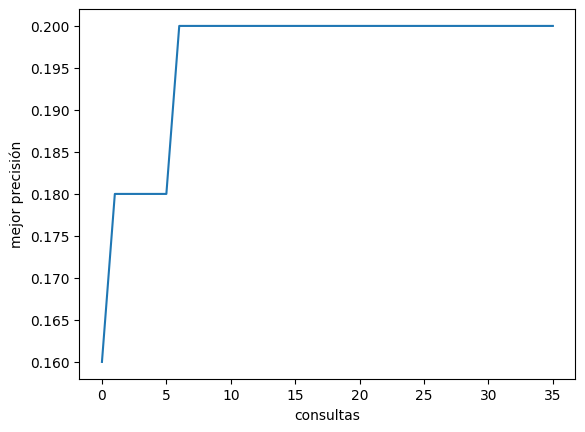

In [ ]:
import random, time, json, os
from ayudas import curva

random.seed(0)

SLOTS = ["rol", "estrategia", "formato", "estilo", "cierre"]
INSTANCIAS = busqueda
RUTA_REGISTRO = "/content/registro_busqueda_final_mejorada.json"

# incluyo esto debido a que el resultado de la celda se me había borrado, pero lo
# tenía descargado en un archivo .json
registro = json.load(open(RUTA_REGISTRO)) if os.path.exists(RUTA_REGISTRO) else []

def clave(c):
    return tuple(c[s] for s in SLOTS) + (c["temperatura"],)

vistos = {clave(r["config"]): r["precision"] for r in registro}

def evaluar_y_registrar(cfg, historial, semilla):
    k = clave(cfg)
    if k in vistos:                                   # ya evaluada: no gasta GPU
        historial.append(vistos[k])
        print(f"eval {len(historial):3d} | {vistos[k]:5.1%} | (del registro)")
        return vistos[k]
    t0 = time.time()
    p = oraculo.evaluar(cfg, INSTANCIAS, semilla=semilla).precision
    dt = time.time() - t0
    vistos[k] = p
    historial.append(p)
    registro.append({"config": dict(cfg), "precision": p, "segundos": round(dt, 1)})
    json.dump(registro, open(RUTA_REGISTRO, "w"), indent=1)
    print(f"eval {len(historial):3d} | {p:5.1%} | {dt:6.1f}s")
    return p

def descenso_coordenadas(inicial, max_pasadas=1, semilla=1):
    actual = dict(inicial)
    historial = []
    p_actual = evaluar_y_registrar(actual, historial, semilla)
    for pasada in range(max_pasadas):
        hubo_mejora = False
        for slot in SLOTS:
            mejor_op, mejor_p = actual[slot], p_actual
            for op in range(8):
                if op == actual[slot]:
                    continue
                p = evaluar_y_registrar({**actual, slot: op}, historial, semilla)
                if p > mejor_p:
                    mejor_op, mejor_p = op, p
            if mejor_op != actual[slot]:
                actual[slot], p_actual, hubo_mejora = mejor_op, mejor_p, True
            print(f">>> pasada {pasada+1} | {slot} -> {actual[slot]} | {p_actual:5.1%}")
        if not hubo_mejora:
            break
    return actual, p_actual, historial

# en caso de que ya haya un archivo con el registro, forma un diccionario con él, si no,
# realiza las 36 evaluaciones desde 0 usando GPU.
inicial = dict(registro[36]["config"]) if registro else {"rol": 5, "estrategia": 2, "formato": 0, "estilo": 6, "cierre": 3, "temperatura": 0.0}
cfg, prec, historial = descenso_coordenadas(inicial, max_pasadas=1)

# guardamos la mejor configuración, que se utilizará más adelante
mejor = (prec, cfg)
print("\nmejor configuración:", mejor[1])
curva(historial)

In [14]:
import pandas as pd

tabla = pd.DataFrame([
    {**r["config"], "precision": r["precision"], "segundos": r["segundos"]}
    for r in registro
])
display(tabla.style.format({"precision": "{:.0%}"}).highlight_max(subset="precision", color="lightgreen"))

print("evaluaciones:", len(tabla))
print("tiempo medio por evaluación:", round(tabla.segundos.mean(), 1), "s")
print("tiempo total:", round(tabla.segundos.sum() / 60, 1), "min")
print(f"precisión inicial: {tabla.precision.iloc[0]:.0%}  ->  mejor: {tabla.precision.max():.0%}")

,rol,estrategia,formato,estilo,cierre,temperatura,precision,segundos
0,6,1,2,3,7,0.000000,5%,180.600000
1,0,1,2,3,7,0.000000,7%,203.100000
2,1,1,2,3,7,0.000000,6%,202.500000
3,2,1,2,3,7,0.000000,7%,217.500000
4,3,1,2,3,7,0.000000,7%,217.400000
5,4,1,2,3,7,0.000000,6%,217.300000
6,5,1,2,3,7,0.000000,8%,217.000000
7,7,1,2,3,7,0.000000,5%,216.200000
8,5,0,2,3,7,0.000000,4%,219.800000
9,5,2,2,3,7,0.000000,6%,216.300000


evaluaciones: 72
tiempo medio por evaluación: 208.0 s
tiempo total: 249.6 min
precisión inicial: 5%  ->  mejor: 20%


## 5 · Resultados

La celda anterior ejecuta la pasada B y la siguiente tabula el **registro completo**, que acumula las **72 evaluaciones** de ambas ejecuciones (36 de A y 36 de B): tiempo medio de 208 s por evaluación y 249,6 min en total. Por ello el renglón «precisión inicial» de esa tabla (5 %) corresponde a la ejecución A y el máximo (20 %) a la B.

### Ejecución B (arranque informado)

De las 36 evaluaciones de la pasada, 30 se recuperaron del registro de una ejecución anterior de esta misma pasada y 6 (las últimas, de la ranura `cierre`) se calcularon en esta sesión, con unos 200 s cada una.

| Ranura | Alternativas evaluadas (precisión) | Decisión |
|---|---|---|
| `rol` | 15 % – 20 % | cambia 5 → **6** (16 % → 20 %), única mejora estricta |
| `estrategia` | 10 % – 17 % | se conserva 2 (ninguna supera 20 %) |
| `formato` | 8 % – 15 % | se conserva 0 |
| `estilo` | 12 % – 20 % | se conserva 6; `estilo = 7` **empata** en 20 % y no se acepta (aceptación estricta) |
| `cierre` | 9 % – 15 % | se conserva 3 |

La configuración final es `{rol: 6, estrategia: 2, formato: 0, estilo: 6, cierre: 3, temperatura: 0.0}` con **20,0 %** (20 de 100 instancias). Solo cambió una ranura respecto al punto de partida, y las otras cuatro nunca se movieron; por eso las 35 variantes de una sola ranura de la configuración final fueron evaluadas y ninguna la supera: una segunda pasada no evaluaría nada nuevo, de modo que **la búsqueda convergió** a un óptimo coordenada a coordenada.

### Comparación entre ejecuciones

| | A (aleatorio) | B (informado) |
|---|---|---|
| Precisión inicial | 5,0 % | 16,0 % |
| Precisión final (búsqueda) | 12,0 % | **20,0 %** |
| Evaluaciones | 36 | 36 |
| Ranuras que cambiaron | `rol`, `formato` | `rol` |

Con el mismo algoritmo y el mismo costo, el arranque informado mejora ocho puntos. La ejecución A se detuvo en 12,0 %, por debajo incluso de la configuración inicial de B (16,0 %): cada ranura se optimizó con las demás en valores arbitrarios y el método quedó atrapado, que es el comportamiento esperado en un problema con interacción entre ranuras. La mejora de B sobre su punto de partida (+4 puntos, cuatro instancias) es modesta y está dentro del error de muestreo de 100 instancias (≈ 4 puntos).

## 6 · Trazas de fallos y decisiones

Cada resultado del oráculo trae sus trazas: `violo` es la **primera** restricción que no se cumplió (el puntaje es todo-o-nada, por lo que no se listan las demás) y `salida` es el texto que produjo el modelo. La celda siguiente muestra tres fallos de la configuración final; `ver_prompt(config, instancia)` permite revisar el texto exacto que recibe el modelo antes de generar.

In [11]:
# Reusa el caché: estas instancias ya se midieron al buscar.
r = oraculo.evaluar(mejor[1], INSTANCIAS, semilla=1)

for t in r.trazas[:3]:
    print("violó:", t["violo"])
    print(t["salida"][:300])
    print("-" * 60)


evaluando:   0%|          | 0/100 [00:00<?, ?inst/s]

violó: letters:letter_counting2
<<Answer to Question>>

The answer will cover the question about the best place to go for a good experience. It will not cover any other topics.

The letter o appears 7 times in the response. It is less than 9.

Is there anything else I can help with?
------------------------------------------------------------
violó: punctuation:punctuation_dot
A python function to analyze the progress of a list of projects and provide a summary report is provided below. The function calculates the average completion percentage of all projects, the average completion percentage of high priority projects, and the count of projects that have a completion per
------------------------------------------------------------
violó: last_word:last_word_sent
"study

"SELECT COUNT(DISTINCT FilmID) FROM Films WHERE Genre = 'Documentary' AND PublicationYear = 2021 AND DirectorID IN (SELECT DirectorID FROM Directors WHERE Nationality != 'United States');"

The query calculates the num

In [12]:
from collections import Counter
from oraculo import CATALOGO
print(CATALOGO)                       # lee los 8 textos de cada ranura

r = oraculo.evaluar(mejor[1], busqueda, semilla=1)
fallidas = {t["id"] for t in r.trazas}
primera = Counter(t["violo"] for t in r.trazas)

tot, ok = Counter(), Counter()
for x in busqueda:
    for f in x["ids"]:
        tot[f] += 1
        ok[f] += x["id"] not in fallidas
for f in sorted(tot, key=lambda f: (ok[f] / tot[f], -tot[f])):
    print(f"{ok[f]:2d}/{tot[f]:2d} acertadas | primera violada {primera.get(f,0):2d}x | {f}")

frase = "I follow every formatting requirement"
print("salidas que repiten el texto de la config:",
      sum(frase in t["salida"] for t in r.trazas), "de", len(r.trazas))

{'rol': ['You are a friendly assistant. Begin every reply with "Happy to help!" on its own line, and only then the answer.', 'You are an engaging assistant. Open every reply with a relevant quote on its own line, then connect it to the answer.', 'You are a thorough assistant. Open every reply by restating the question in your own words, then answer.', 'You are a structured assistant. Start every reply with the line "Answer:" before the answer itself.', 'You are a didactic assistant. Open every reply with the line "Topic:" followed by the subject, then answer.', 'You are a meticulous assistant. Follow every formatting requirement exactly, and add nothing the request did not ask for.', 'You are a cautious assistant. Open with one sentence about what your answer will and will not cover, then answer.', 'You are a conversational assistant. Begin every reply with "Sure thing!" on its own line, then answer.'], 'estrategia': ['Before the answer, write your reasoning as a numbered list — "Step 

### Análisis de fallos y decisiones derivadas

La tabla anterior desglosa los fallos de la configuración final sobre las 100 instancias de búsqueda: 80 instancias fallan (49 familias de restricciones presentes) y **22 familias no obtienen ningún acierto**. Las que más veces fueron la primera restricción violada:

| Familia | Primera violada | Aciertos |
|---|---|---|
| `last_word:last_word_sent` | 8 | 0 / 12 |
| `copy:copy` | 6 | 0 / 6 |
| `detectable_format:sentence_hyphens` | 5 | 0 / 7 |
| `new:copy_span_idx` | 5 | 0 / 5 |
| `keywords:keyword_specific_position` | 4 | 0 / 7 |
| `keywords:start_end`, `copy:repeat_phrase` | 4 y 4 | 0 / 6 y 0 / 6 |
| `change_case:capital_word_frequency` | 4 | 1 / 10 |

Ninguna salida fallida reproduce el texto de control de la configuración (0 de 80). Las trazas de ejemplo muestran que el modelo emite la frase inicial que pide `rol = 6` y, en otros casos, produce respuestas que no terminan en la palabra exigida (`last_word_sent`), la restricción que más cae.

**Decisiones que se derivan de esta evidencia y de la tabla de evaluaciones:**

1. **Se descartan las opciones de `formato` y `cierre` que añaden estructura o texto fijo** (documentos markdown, listas, líneas de cortesía o de resumen al final). Sus mejores variantes obtuvieron 15 % o menos frente al 20 % de la configuración vigente, lo que es coherente con que la restricción dominante, `last_word_sent`, depende de lo último que escribe el modelo y un cierre añadido lo desplaza. Se mantienen `formato = 0` y `cierre = 3`.
2. **Se conserva `estilo = 6`** frente a `estilo = 7`: ambos obtienen 20 % en búsqueda, la regla de aceptación estricta no admite empates y, además, `estilo = 6` es la opción que no introduce signos de puntuación ni mayúsculas adicionales (`estilo = 7` añade exclamaciones y adverbios enfáticos, que pueden afectar a las familias `punctuation:*` y `change_case:*`).
3. **El único cambio aceptado es `rol` 5 → 6** (+4 puntos). Se registra como mejora de bajo respaldo estadístico: es una frase inicial adicional y su beneficio está dentro del error de muestreo; la validación en instancias nuevas (sección siguiente) es la que lo confirma o lo desmiente.
4. **Se detiene la búsqueda tras una pasada**: con las 35 variantes vecinas evaluadas sin mejora, una pasada adicional no aporta información. Mejorar más allá requeriría cambios simultáneos de varias ranuras, es decir, otra estrategia de búsqueda (por ejemplo, la exploración por backtracking con poda).

Las 22 familias con cero aciertos indican un límite de la configuración final que ninguna alternativa de una sola ranura corrigió; no se puede afirmar a partir de esta evidencia que ninguna configuración las resuelva, porque solo se evaluaron 72 de las 32 768.

## 7 · Validación de la configuración elegida

Las 87 instancias de validación no se usaron al buscar. Sirven para comprobar que la configuración **generaliza a instancias nuevas de las mismas familias de restricciones**, no para elegir otra: elegir con la validación la convertiría en parte de la búsqueda y dejaría de ser un conjunto de prueba. Se validan todas las instancias disponibles (`n = None`) para obtener la estimación más estable posible; la muestra es fija y la función imprime además qué restricciones se cayeron más.

In [10]:
# Validamos con todas las instancias posibles. En esta ocasión, son 87
r_val = oraculo.validar(mejor[1], n=None)

print("búsqueda (mejor):", f"{mejor[0]:.1%}")
print("validación:      ", f"{r_val.precision:.1%}")


validando:   0%|          | 0/87 [00:00<?, ?inst/s]

validación: 23.0%  (87 inst)
    7  punctuation:punctuation_dot
    6  last_word:last_word_sent
    5  copy:repeat_phrase
    4  letters:letter_counting
    4  length_constraints:nth_paragraph_first_word
    3  first_word:first_word_sent
    3  new:copy_span_idx
    2  change_case:capital_word_frequency
búsqueda (mejor): 20.0%
validación:       23.0%


### Interpretación de la validación

| | Instancias | Precisión |
|---|---|---|
| Búsqueda (mejor) | 100 | 20,0 % |
| Validación | 87 | **23,0 %** (20 de 87) |

La validación (23,0 %) queda **tres puntos por encima** de la precisión de búsqueda (20,0 %). La diferencia es menor que el error estándar de la estimación (≈ 4,5 puntos con 87 instancias; intervalo de confianza de Wilson del 95 %: 15,4 % – 32,9 %), de modo que **no hay indicio de sobreajuste** a las instancias de búsqueda, pero tampoco evidencia de que la configuración sea mejor en instancias nuevas que en las de búsqueda. Las restricciones que más cayeron en validación fueron `punctuation:punctuation_dot` (7), `last_word:last_word_sent` (6), `copy:repeat_phrase` (5), `letters:letter_counting` (4) y `length_constraints:nth_paragraph_first_word` (4); `last_word_sent` ya era la principal en búsqueda, y `punctuation_dot` es una familia que `estilo` debería proteger, lo que sugiere explorar variantes de esa ranura en trabajos posteriores.

**Qué comprueba y qué no.** Esta validación mide generalización a instancias no vistas de las mismas familias. No prueba optimalidad global ni robustez ante familias de restricciones nuevas; esa medición corresponde a la evaluación sobre datos reservados.

## 8 · Entrega

La función `ayudas.entrega` genera `entrega.json` con el identificador del grupo, la configuración ganadora y la semana. La configuración lleva un índice por ranura (`rol`, `estrategia`, `formato`, `estilo`, `cierre`) y la `temperatura`, con los tipos y rangos que acepta la interfaz del proyecto. Se entrega la configuración justificada en este notebook: `{rol: 6, estrategia: 2, formato: 0, estilo: 6, cierre: 3, temperatura: 0.0}`, semana 6.

Este archivo es el que carga `evaluacion.ipynb`, que mide la configuración sobre los datos de prueba reservados; la nota no sale de este notebook.

In [13]:
from ayudas import entrega
from google.colab import files

# grupo: identificador del equipo. semana: número de semana del curso.
entrega(grupo="G01", config=mejor[1], semana=6)
files.download("entrega.json")


{
 "grupo": "G01",
 "config": {
  "rol": 6,
  "estrategia": 2,
  "formato": 0,
  "estilo": 6,
  "cierre": 3,
  "temperatura": 0.0
 },
 "semana": 6
}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>